In [2]:
import numpy as np

perch_length = np.array([8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0, 21.0,
       21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5, 22.5, 22.7,
       23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5, 27.3, 27.5, 27.5,
       27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0, 36.5, 36.0, 37.0, 37.0,
       39.0, 39.0, 39.0, 40.0, 40.0, 40.0, 40.0, 42.0, 43.0, 43.0, 43.5,
       44.0])
perch_weight = np.array([5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0, 110.0,
       115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0, 130.0,
       150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0, 197.0,
       218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0, 514.0,
       556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0, 820.0,
       850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0, 1000.0,
       1000.0])

In [3]:
from sklearn.model_selection import train_test_split

# train test set
train_input, test_input, train_target, test_target = train_test_split(perch_length, perch_weight, random_state=42)

# 2차원 배열로 변환
train_input = train_input.reshape(-1, 1)
test_input = test_input.reshape(-1, 1)

In [5]:
# 이웃 개수 3으로 하는 모델
from sklearn.neighbors import KNeighborsRegressor

knr = KNeighborsRegressor(n_neighbors=3)

# 모델 훈련
knr.fit(train_input, train_target)

KNeighborsRegressor(n_neighbors=3)

In [7]:
# 50cm 농어 무게 예측
print(knr.predict([[50]]))

[1033.33333333]


실제 농어 무게는 훨씬 더 많이 나감

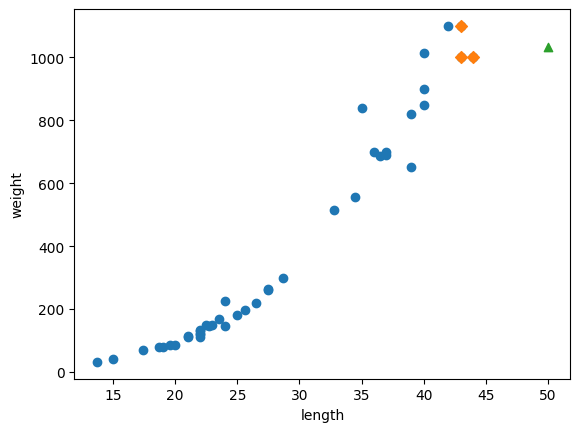

In [8]:
import matplotlib.pyplot as plt

# 50cm 농어의 이웃
distances, indexes = knr.kneighbors([[50]])

plt.scatter(train_input, train_target)

# 이웃만 그리기
plt.scatter(train_input[indexes], train_target[indexes], marker='D')

# 예측값
plt.scatter(50, 1033, marker='^')
plt.xlabel('length')
plt.ylabel('weight')
plt.show()

산점도를 보면 길이가 길어질수록 무게가 증가하는 경향

KNN 알고리즘은 샘플들의 무게를 평균

In [9]:
print(np.mean(train_target[indexes]))

1033.3333333333333


#### 선형회귀(Linear Regression)



In [10]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()

# 모델 훈련
lr.fit(train_input, train_target)

# 50cm 농어 예측
print(lr.predict([[50]]))

[1241.83860323]


In [11]:
print(lr.coef_, lr.intercept_)

[39.01714496] -709.0186449535477


KNN의 경우 모델 파라미터 X -> 사례 기반 학습

대부분의 머신러닝 알고리즘은 최적의 모델 파라미터를 찾아야함 -> 모델 기반 학습

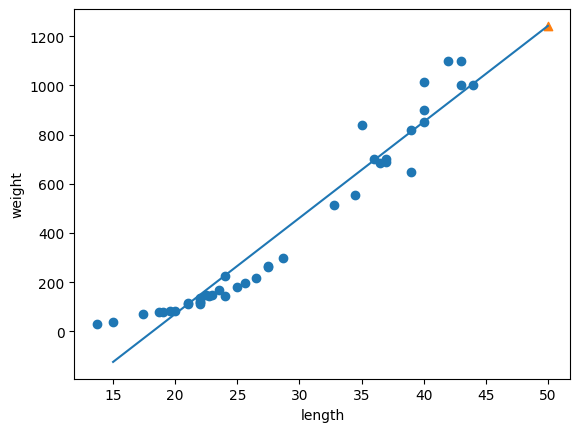

In [15]:
# train set 산점도
plt.scatter(train_input, train_target)

# 15에서 50까지 1차 방정식
plt.plot([15, 50], [15*lr.coef_+lr.intercept_, 50*lr.coef_+lr.intercept_])

# 50cm 농어 데이터
plt.scatter(50, 1241.8, marker='^')
plt.xlabel('length')
plt.ylabel('weight')
plt.show()

In [16]:
# 결정계수
print(lr.score(train_input, train_target))
print(lr.score(test_input, test_target))

0.939846333997604
0.8247503123313558


과대적합 ❓ 과소적합 ❓

직선으로는 예측 힘듬. 이 직선대로라면 농어의 무게가 0g 이하로 내려갈 수 있음.



In [17]:
#### 다항 회귀
train_poly = np.column_stack((train_input ** 2, train_input))
test_poly = np.column_stack((test_input ** 2, test_input))

print(train_poly.shape, test_poly.shape)

(42, 2) (14, 2)


In [18]:
lr = LinearRegression()
lr.fit(train_poly, train_target)

print(lr.predict([[50**2, 50]]))

[1573.98423528]


In [19]:
print(lr.coef_, lr.intercept_)

[  1.01433211 -21.55792498] 116.0502107827827


무게 = 1.01 x 길이^2 -21.6 x 길이 + 116.05

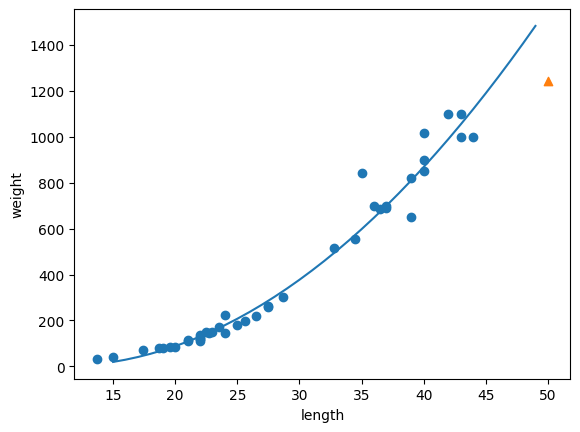

In [20]:
# 구간별 직선을 그리기 위해 15에서 49까지 정수 배열 생성
point = np.arange(15, 50)

plt.scatter(train_input, train_target)

# 15에서 49까지 2차 방정식
plt.plot(point, 1.01*point**2 - 21.6*point + 116.05)

# 50cm 농어 데이터
plt.scatter(50, 1241.8, marker='^')
plt.xlabel('length')
plt.ylabel('weight')
plt.show()

In [21]:
# 결정계수
print(lr.score(train_poly, train_target))
print(lr.score(test_poly, test_target))

0.9706807451768623
0.9775935108325122


과소적합이 남아있음